# 4. Variante global–regional

En el cuaderno 03, la grieta fue la clase con más omisiones para ConvNeXt-Tiny. Se mantiene esa red como rama global y se incorpora una rama que mira recortes para comprobar si recupera grietas en validación.

In [1]:
import json
import math
import os
import time

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.metrics import f1_score
from torch import nn
from torch.nn import functional as F
from torch.optim import AdamW
from torch.utils.data import DataLoader
from torchinfo import summary
from torchvision.models import ConvNeXt_Tiny_Weights, convnext_tiny

from photovoltaic_xai import CLASS_NAMES
from photovoltaic_xai.dataset import PairedELTransform, letterbox
from photovoltaic_xai.metrics import compute_metrics, optimize_thresholds
from photovoltaic_xai.models import (
    parameter_groups,
    save_json,
    save_run,
    seed_everything,
    warmup_cosine,
)
from photovoltaic_xai.notebook_support import figure_style, project_root, show_figure
from photovoltaic_xai.preparation import load_preparation
from photovoltaic_xai.variant import (
    LOCAL_CLASS_NAMES,
    CachedViews,
    GlobalRegionalClassifier,
    RegionDataset,
    RegionFusion,
    VariantDataset,
    attention_targets,
    balanced_attention_loss,
    build_regions,
    file_hash,
    load_or_extract_features,
    masked_region_loss,
    pair_balance_weights,
    tile_geometry,
)

PROJECT_ROOT = project_root()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
plt.rcParams.update(figure_style())
print("Dispositivo:", device)

Dispositivo: cuda


## Una vista global y 25 ventanas

Cargamos las particiones, los umbrales de ConvNeXt y los identificadores de las grietas difíciles. La rama global recibe la imagen a 512 × 512. La regional extrae 25 ventanas de 256 × 256 de un lienzo de 1024 × 1024 y las reduce a 224 × 224. La tabla cuenta las imágenes de cada partición.

In [2]:
prepared = load_preparation(PROJECT_ROOT)
normalization = prepared["normalization"]
train_records = [r for r in prepared["records"] if r["split"] == "train"]
val_records = [r for r in prepared["records"] if r["split"] == "val"]
records_by_id = {r["id"]: r for r in train_records + val_records}
expected_ids = np.asarray([r["id"] for r in val_records])
expected_labels = np.asarray([r["labels"] for r in val_records], dtype=np.float32)
geometry = {"global_size": 512, "canvas_size": 1024, "tile_size": 256, "local_size": 224}
_, positions = tile_geometry()
positions = positions.to(device)
REGIONAL_DIR = PROJECT_ROOT / "outputs/variant/regional"
OUTPUT_DIR = PROJECT_ROOT / "outputs/variant_reference_global"
REGIONAL_CONFIG = {
    "seed": 42,
    "image_size": 224,
    "batch_size": 32,
    "max_epochs": 15,
    "patience": 3,
    "warmup_epochs": 1,
    "lr_backbone": 1e-4,
    "lr_head": 5e-4,
    "weight_decay": 0.01,
    "context_scale": 1.5,
    "min_context_fraction": 0.125,
    "amp": True,
    "device": str(device),
}
CONFIG = {
    "seed": 42,
    "device": str(device),
    "batch_size": 128,
    "hidden": 128,
    "max_epochs": 30,
    "patience": 5,
    "lr": 1e-3,
    "weight_decay": 0.01,
    "regional_weight": 0.25,
    "alignment_weight": 0.1,
}
SEEDS = (42, 43, 44)
paths = {
    "global_weights": "outputs/experiments/convnext_tiny/best.pt",
    "global_run": "outputs/experiments/convnext_tiny/run.json",
    "global_validation": "outputs/experiments/convnext_tiny/validation.npz",
    "regional_weights": "outputs/variant/regional/best.pt",
    "regional_run": "outputs/variant/regional/run.json",
    "fusion_dir": "outputs/variant_reference_global/fusion",
    "features_train": "outputs/variant_reference_global/features_train",
    "features_val": "outputs/variant_reference_global/features_val",
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# The diagnostic cohort is a versioned input, not an output of old model searches.
cohort = json.loads((PROJECT_ROOT / "docs/research/evidence/hard-crack-cohort.json").read_text())
if cohort["data"]["data_fingerprint"] != prepared["data_fingerprint"]:
    raise ValueError("The historical diagnostic cohort belongs to another prepared dataset")
hard_ids = cohort["cohort"]["ids"]
val_by_id = {r["id"]: r for r in val_records}
if len(hard_ids) != len(set(hard_ids)) or any(
    identifier not in val_by_id or not val_by_id[identifier]["labels"][0] for identifier in hard_ids
):
    raise ValueError("The diagnostic cohort must contain unique positive validation cracks")
global_run = json.loads((PROJECT_ROOT / paths["global_run"]).read_text())
if (
    global_run.get("status") != "complete"
    or global_run["metadata"]["data_fingerprint"] != prepared["data_fingerprint"]
    or global_run["class_names"] != list(CLASS_NAMES)
):
    raise ValueError("Complete the ConvNeXt reference on the current prepared data first")
global_thresholds = np.asarray(global_run["metrics"]["thresholds"], dtype=float)
if global_thresholds.shape != (6,) or not np.isfinite(global_thresholds).all():
    raise ValueError("The global branch requires six frozen validation thresholds")
display(pd.DataFrame({"training": [len(train_records)], "validation": [len(val_records)]}))

,training,validation
0,23267,5000


Partimos de 23 267 imágenes de entrenamiento y 5 000 de validación. Los recortes respetan esa separación.

## Datos para el extractor regional

Preparamos recortes centrados en cajas válidas de grieta, interrupción de dedo y línea gruesa. En entrenamiento combinamos recortes nativos con recortes de imágenes reducidas a 512 y restauradas. En validación usamos las dos vistas por separado. La tabla cuenta las cajas que sirven de centro y muestra el peso de cada clase en la pérdida.

In [3]:
regions = build_regions(train_records + val_records)
train_regions = [r for r in regions if r["split"] == "train"]
val_regions = [r for r in regions if r["split"] == "val"]
if {records_by_id[r["image_id"]]["group_id"] for r in train_regions} & {
    records_by_id[r["image_id"]]["group_id"] for r in val_regions
}:
    raise ValueError("Regional training and validation groups overlap")
class_counts = np.bincount([r["class_index"] for r in train_regions], minlength=3)
if np.any(class_counts == 0):
    raise ValueError("Each regional category needs clean training anchors")
class_weights = len(train_regions) / (3 * class_counts)
train_transform = PairedELTransform(
    224, mean=normalization["mean"], std=normalization["std"], training=True, noise_std=0
)
val_transform = PairedELTransform(224, mean=normalization["mean"], std=normalization["std"])
regional_train_loader = DataLoader(
    RegionDataset(train_regions, records_by_id, PROJECT_ROOT, train_transform, view="mixed"),
    batch_size=REGIONAL_CONFIG["batch_size"],
    shuffle=True,
    generator=torch.Generator().manual_seed(REGIONAL_CONFIG["seed"]),
)
regional_val_loaders = {
    view: DataLoader(
        RegionDataset(val_regions, records_by_id, PROJECT_ROOT, val_transform, view=view),
        batch_size=REGIONAL_CONFIG["batch_size"],
        shuffle=False,
    )
    for view in ("native", "reduced")
}
display(
    pd.DataFrame(
        {
            "class": LOCAL_CLASS_NAMES,
            "training_anchors": class_counts,
            "validation_anchors": np.bincount([r["class_index"] for r in val_regions], minlength=3),
            "CE_weight": class_weights,
        }
    )
)

,class,training_anchors,validation_anchors,CE_weight
0,crack,2567,554,2.633814
1,finger,15953,3425,0.423807
2,thick_line,1763,343,3.834940


`CE_weight` es el peso de cada clase en la pérdida de entropía cruzada. Se da más peso a los recortes de las clases con menos ejemplos. Por eso la interrupción de dedo, con 15 953 cajas de entrenamiento, recibe el peso más bajo (0,42) y la línea gruesa, con 1 763, el más alto (3,83).

## Modelo regional

Preparamos un ConvNeXt-Tiny con tres salidas para clasificar los recortes. Para un ajuste nuevo, partimos de los pesos de ImageNet.

In [4]:
regional_path = REGIONAL_DIR / "run.json"
regional_run = json.loads(regional_path.read_text()) if regional_path.exists() else None
if regional_run is not None:
    saved = regional_run["inputs"]
    scientific_config = {k: v for k, v in saved["config"].items() if k != "device"}
    if (
        regional_run.get("status") != "complete"
        or saved["data_fingerprint"] != prepared["data_fingerprint"]
        or scientific_config != {k: v for k, v in REGIONAL_CONFIG.items() if k != "device"}
        or regional_run["region_class_names"] != list(LOCAL_CLASS_NAMES)
    ):
        raise ValueError("The saved regional encoder is incomplete or scientifically incompatible")
    np.testing.assert_allclose(regional_run["class_weights"], class_weights, rtol=0, atol=1e-12)
seed_everything(REGIONAL_CONFIG["seed"])
regional_encoder = convnext_tiny(
    weights=None if regional_run is not None else ConvNeXt_Tiny_Weights.IMAGENET1K_V1
)
regional_encoder.classifier[-1] = nn.Linear(regional_encoder.classifier[-1].in_features, 3)
regional_encoder.to(device)
display(summary(regional_encoder, depth=3, col_names=("num_params", "trainable"), verbose=0))

Layer (type:depth-idx)                        Param #                   Trainable
ConvNeXt                                      --                        True
├─Sequential: 1-1                             --                        True
│    └─Conv2dNormActivation: 2-1              --                        True
│    │    └─Conv2d: 3-1                       4,704                     True
│    │    └─LayerNorm2d: 3-2                  192                       True
│    └─Sequential: 2-2                        --                        True
│    │    └─CNBlock: 3-3                      79,296                    True
│    │    └─CNBlock: 3-4                      79,296                    True
│    │    └─CNBlock: 3-5                      79,296                    True
│    └─Sequential: 2-3                        --                        True
│    │    └─LayerNorm2d: 3-6                  192                       True
│    │    └─Conv2d: 3-7                       73,920                   

El resumen muestra 27 822 435 parámetros entrenables. Esta primera etapa ajusta el extractor completo.

## Entrenamiento del extractor regional

Entrenamos el extractor con la pérdida ponderada. Seleccionamos la época con el mayor F1 macro medio de las dos escalas y congelamos esos pesos para la fusión.

In [5]:
if regional_run is None:
    REGIONAL_DIR.mkdir(parents=True, exist_ok=True)
    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(class_weights, dtype=torch.float32, device=device)
    )
    optimizer = AdamW(
        parameter_groups(
            regional_encoder, REGIONAL_CONFIG["lr_backbone"], REGIONAL_CONFIG["lr_head"]
        ),
        weight_decay=REGIONAL_CONFIG["weight_decay"],
    )
    total_updates = REGIONAL_CONFIG["max_epochs"] * len(regional_train_loader)
    warmup = REGIONAL_CONFIG["warmup_epochs"] * len(regional_train_loader)

    scheduler = warmup_cosine(optimizer, warmup, total_updates)
    use_amp = REGIONAL_CONFIG["amp"] and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    regional_run = {
        "protocol": "annotated-region-diagnostic-v1",
        "status": "running",
        "inputs": {
            "config": dict(REGIONAL_CONFIG),
            "data_fingerprint": prepared["data_fingerprint"],
        },
        "region_class_names": list(LOCAL_CLASS_NAMES),
        "class_weights": class_weights.tolist(),
        "completed_epochs": 0,
        "completed_updates": 0,
        "skipped_updates": 0,
    }
    history, best_f1, stale = [], -math.inf, 0
    started = time.perf_counter()
    save_run(REGIONAL_DIR, regional_run)
    for epoch in range(1, REGIONAL_CONFIG["max_epochs"] + 1):
        regional_encoder.train()
        loss_sum, weight_sum = 0.0, 0.0
        previous_updates = regional_run["completed_updates"]
        for batch in regional_train_loader:
            images, targets = batch["image"].to(device), batch["target"].to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=use_amp):
                loss = criterion(regional_encoder(images), targets)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite regional loss")
            scaler.scale(loss).backward()
            previous_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            if scaler.get_scale() >= previous_scale:
                regional_run["completed_updates"] += 1
                scheduler.step()
            else:
                regional_run["skipped_updates"] += 1
            batch_weight = float(criterion.weight[targets].sum())
            loss_sum += float(loss.detach()) * batch_weight
            weight_sum += batch_weight
        if regional_run["completed_updates"] == previous_updates:
            raise RuntimeError("No regional optimizer update in this epoch")
        regional_encoder.eval()
        scores, losses = {}, []
        for view, loader in regional_val_loaders.items():
            logits_parts, targets_parts = [], []
            with torch.inference_mode(), torch.autocast(device.type, enabled=False):
                for batch in loader:
                    logits_parts.append(regional_encoder(batch["image"].to(device)).float().cpu())
                    targets_parts.append(batch["target"])
            logits, targets = torch.cat(logits_parts), torch.cat(targets_parts)
            if not torch.isfinite(logits).all():
                raise RuntimeError("Non-finite regional validation predictions")
            scores[view] = f1_score(
                targets, logits.argmax(1), labels=[0, 1, 2], average="macro", zero_division=0
            )
            losses.append(criterion(logits.to(device), targets.to(device)).item())
        score = float(np.mean(list(scores.values())))
        if score > best_f1:
            best_f1, stale = score, 0
            regional_run.update(best_epoch=epoch, best_macro_f1=score)
            torch.save(regional_encoder.state_dict(), REGIONAL_DIR / "best.pt")
        else:
            stale += 1
        history.append(
            {
                "epoch": epoch,
                "train_loss": loss_sum / weight_sum,
                "val_loss": float(np.mean(losses)),
                "native_macro_f1": scores["native"],
                "reduced_macro_f1": scores["reduced"],
                "selection_macro_f1": score,
                "completed_updates": regional_run["completed_updates"],
                "skipped_updates": regional_run["skipped_updates"],
            }
        )
        regional_run["completed_epochs"] = epoch
        print(f"Extractor regional, época {epoch}: CE={loss_sum / weight_sum:.4f}, F1={score:.4f}")
        if stale >= REGIONAL_CONFIG["patience"]:
            break
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    regional_run.update(
        status="complete",
        training_seconds=time.perf_counter() - started,
        stop_reason="early_stopping" if stale >= REGIONAL_CONFIG["patience"] else "max_epochs",
    )
    pd.DataFrame(history).to_csv(REGIONAL_DIR / "history.csv", index=False)
    save_run(REGIONAL_DIR, regional_run)
else:
    print("Pesos del extractor regional recuperados")
regional_encoder.load_state_dict(
    torch.load(REGIONAL_DIR / "best.pt", map_location=device, weights_only=True)
)
regional_encoder.requires_grad_(False).eval()

Extractor regional, época 1: CE=0.2487, F1=0.9301
Extractor regional, época 2: CE=0.0811, F1=0.9047
Extractor regional, época 3: CE=0.0656, F1=0.9855
Extractor regional, época 4: CE=0.0559, F1=0.9846
Extractor regional, época 5: CE=0.0534, F1=0.9780
Extractor regional, época 6: CE=0.0536, F1=0.9875
Extractor regional, época 7: CE=0.0467, F1=0.9815
Extractor regional, época 8: CE=0.0426, F1=0.9850
Extractor regional, época 9: CE=0.0441, F1=0.9821


ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=96, out_features=384, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=384, out_features=96, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=

## Validación del extractor regional

La tabla muestra la pérdida de validación y el F1 macro de los recortes nativos y reducidos en la época elegida. `selection_macro_f1` es la media de ambos F1.

In [6]:
regional_history = pd.read_csv(REGIONAL_DIR / "history.csv")
display(
    regional_history.loc[
        regional_history.epoch == regional_run["best_epoch"],
        ["epoch", "val_loss", "native_macro_f1", "reduced_macro_f1", "selection_macro_f1"],
    ]
)

,epoch,val_loss,native_macro_f1,reduced_macro_f1,selection_macro_f1
5,6,0.073861,0.987684,0.987305,0.987495


En la época 6, el F1 macro fue del 98,77 % en recortes nativos y del 98,73 % en los reducidos. El F1 macro medio, usado para elegir la época, fue del 98,75 %.

## Curvas del extractor regional

La izquierda muestra la pérdida por época y la derecha, el F1 macro en las dos escalas y su media. La línea discontinua señala la época que hemos seleccionado.

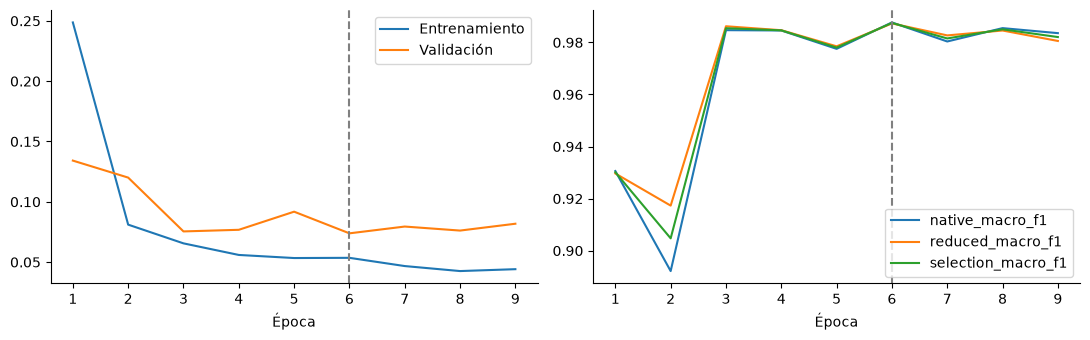

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(regional_history.epoch, regional_history.train_loss, label="Entrenamiento")
axes[0].plot(regional_history.epoch, regional_history.val_loss, label="Validación")
for name in ("native_macro_f1", "reduced_macro_f1", "selection_macro_f1"):
    axes[1].plot(regional_history.epoch, regional_history[name], label=name)
for axis in axes:
    axis.axvline(regional_run["best_epoch"], color="gray", linestyle="--")
    axis.set_xlabel("Época")
    axis.legend()
fig.tight_layout()
plt.show()

Los dos F1 se mantienen próximos desde la tercera época. La pérdida de entrenamiento sigue bajando hasta la octava, después del máximo de F1 de validación en la sexta.

## Modelo global congelado

Cargamos los pesos de ConvNeXt-Tiny del cuaderno 02 y congelamos el modelo. Sus seis salidas son el punto de partida de la fusión.

In [8]:
global_encoder = convnext_tiny(weights=None)
global_encoder.classifier[-1] = nn.Linear(global_encoder.classifier[-1].in_features, 6)
global_encoder.load_state_dict(
    torch.load(PROJECT_ROOT / paths["global_weights"], map_location="cpu", weights_only=True)
)
global_encoder.to(device).requires_grad_(False).eval()

display(summary(global_encoder, depth=3, col_names=("num_params", "trainable"), verbose=0))

Layer (type:depth-idx)                        Param #                   Trainable
ConvNeXt                                      --                        False
├─Sequential: 1-1                             --                        False
│    └─Conv2dNormActivation: 2-1              --                        False
│    │    └─Conv2d: 3-1                       (4,704)                   False
│    │    └─LayerNorm2d: 3-2                  (192)                     False
│    └─Sequential: 2-2                        --                        False
│    │    └─CNBlock: 3-3                      (79,296)                  False
│    │    └─CNBlock: 3-4                      (79,296)                  False
│    │    └─CNBlock: 3-5                      (79,296)                  False
│    └─Sequential: 2-3                        --                        False
│    │    └─LayerNorm2d: 3-6                  (192)                     False
│    │    └─Conv2d: 3-7                       (73,920)      

En el resumen podemos ver que la rama global tiene cero parámetros entrenables.

## Características de los dos extractores

Calculamos las características que utilizará la fusión. Comparamos los logits globales de validación con los guardados por ConvNeXt y contamos cuántas decisiones cambian al aplicar los mismos umbrales.

In [9]:
dimension = global_encoder.classifier[-1].in_features
if regional_encoder.classifier[-1].in_features != dimension:
    raise ValueError("The two encoders use incompatible feature dimensions")
encoder_hashes = {
    name: file_hash(PROJECT_ROOT / paths[name]) for name in ("global_weights", "regional_weights")
}
inputs = {
    "protocol": "reference-global-regional-v1",
    "data_fingerprint": prepared["data_fingerprint"],
    "normalization": normalization,
    "class_names": list(CLASS_NAMES),
    "encoders": encoder_hashes,
    "geometry": geometry,
}
feature_arrays = {}
for split, records in (("train", train_records), ("val", val_records)):
    regional_arrays = load_or_extract_features(
        PROJECT_ROOT / "outputs/variant" / f"features_{split}",
        records,
        regional_encoder,
        inputs,
        PROJECT_ROOT,
        regional=True,
    )
    global_arrays = load_or_extract_features(
        PROJECT_ROOT / paths[f"features_{split}"], records, global_encoder, inputs, PROJECT_ROOT
    )
    feature_arrays[split] = regional_arrays | global_arrays
train_arrays, val_arrays = feature_arrays["train"], feature_arrays["val"]
with np.load(PROJECT_ROOT / paths["global_validation"], allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved["ids"], expected_ids)
    np.testing.assert_array_equal(saved["labels"], expected_labels)
    global_logits = val_arrays["global_logits"]
    max_difference = np.max(np.abs(global_logits - saved["logits"]))
    cached_decisions = torch.from_numpy(global_logits.copy()).sigmoid().numpy() >= global_thresholds
    saved_decisions = torch.from_numpy(saved["logits"]).sigmoid().numpy() >= global_thresholds
display(
    pd.Series(
        {
            "Máxima diferencia de logits": max_difference,
            "Decisiones distintas": np.count_nonzero(cached_decisions != saved_decisions),
        }
    )
)

Máxima diferencia de logits    0.003303
Decisiones distintas           0.000000
dtype: float64

La diferencia máxima entre los logits fue de 0,003303 en validación. Con los mismos umbrales, el recuento de decisiones distintas es cero. Esto significa que los logits globales calculados coinciden prácticamente con los guardados por ConvNeXt.

## Ajustes de la fusión

Con los dos extractores fijos, comparamos la atención con y sin equilibrado para las semillas 42, 43 y 44. La ejecución principal usa el modo equilibrado con la semilla 42. Esta prueba se hace para evaluar la estabilidad de la atención bajo diferentes configuraciones de semilla y modos de equilibrado.

### Modelo de fusión

La fusión combina las características globales con las de las ventanas. Aprende una corrección para cada uno de los seis logits de ConvNeXt.

In [10]:
fusion = RegionFusion(dimension=dimension, hidden=CONFIG["hidden"])
display(summary(fusion, depth=3, col_names=("num_params", "trainable"), verbose=0))
del fusion

Layer (type:depth-idx)                   Param #                   Trainable
RegionFusion                             2,438                     True
├─Sequential: 1-1                        --                        True
│    └─LayerNorm: 2-1                    1,536                     True
│    └─Linear: 2-2                       98,432                    True
├─Sequential: 1-2                        --                        True
│    └─LayerNorm: 2-3                    1,536                     True
│    └─Linear: 2-4                       98,432                    True
│    └─GELU: 2-5                         --                        --
├─Linear: 1-3                            512                       True
├─Linear: 1-4                            16,384                    True
├─Linear: 1-5                            387                       True
Total params: 219,657
Trainable params: 219,657
Non-trainable params: 0

La fusión añade 219 657 parámetros entrenables a los dos extractores congelados.

### Entrenamiento de la fusión

Entrenamos o recuperamos los seis ajustes. La pérdida combina la clasificación de la imagen, las etiquetas de las ventanas y la supervisión de la atención. Para cada ajuste seleccionamos la época con mayor mAP en validación y calculamos sus umbrales F1.

In [11]:
positive_pairs, null_pairs, _ = attention_targets(
    torch.from_numpy(train_arrays["region_targets"].copy()),
    torch.from_numpy(train_arrays["region_known"].copy()),
    torch.from_numpy(train_arrays["tile_valid"].copy()),
)
pair_weights = pair_balance_weights(
    positive_pairs.sum(0), null_pairs.sum(0), len(train_records)
).to(device)
val_loader = DataLoader(CachedViews(val_arrays), batch_size=CONFIG["batch_size"], shuffle=False)
runs = {}
for seed in SEEDS:
    for balanced in (True, False):
        config = dict(CONFIG, seed=seed)
        mode = "balanced" if balanced else "unbalanced"
        attention_mode = f"{mode}_attention"
        directory = (
            OUTPUT_DIR / "fusion"
            if seed == 42 and balanced
            else OUTPUT_DIR / "evaluation" / f"{mode}_seed_{seed}"
        )
        current_inputs = dict(inputs, config=config, attention_mode=attention_mode)
        run_path = directory / "run.json"
        candidate_run = json.loads(run_path.read_text()) if run_path.exists() else None
        if candidate_run is not None:
            saved = candidate_run["identity"]["inputs"]
            if (
                candidate_run.get("status") != "complete"
                or any(
                    saved.get(k) != inputs[k]
                    for k in (
                        "data_fingerprint",
                        "class_names",
                        "normalization",
                        "geometry",
                        "encoders",
                    )
                )
                or saved.get("attention_mode") != attention_mode
                or {k: v for k, v in saved["config"].items() if k != "device"}
                != {k: v for k, v in config.items() if k != "device"}
            ):
                raise ValueError("Saved fusion is incomplete or scientifically incompatible")
            for filename in ("best.pt", "history.csv", "validation.npz"):
                if file_hash(directory / filename) != candidate_run["artifacts"][filename]:
                    raise ValueError(f"Saved fusion artifact changed: {filename}")
            print("Fusión recuperada:", seed, mode)
        else:
            seed_everything(seed)
            candidate = RegionFusion(dimension=dimension, hidden=config["hidden"]).to(device)
            directory.mkdir(parents=True, exist_ok=True)
            train_loader = DataLoader(
                CachedViews(train_arrays),
                batch_size=config["batch_size"],
                shuffle=True,
                generator=torch.Generator().manual_seed(seed),
            )
            optimizer = AdamW(
                candidate.parameters(), lr=config["lr"], weight_decay=config["weight_decay"]
            )
            total_updates, warmup = config["max_epochs"] * len(train_loader), len(train_loader)

            scheduler = warmup_cosine(optimizer, warmup, total_updates)
            candidate_run = {
                "status": "running",
                "identity": {"inputs": current_inputs, "model": attention_mode},
                "class_names": list(CLASS_NAMES),
                "best_epoch": 0,
                "best_map": -math.inf,
                "completed_epochs": 0,
                "updates": 0,
                "presentations": 0,
                "trainable_parameters": sum(p.numel() for p in candidate.parameters()),
            }
            history, stale = [], 0
            started = time.perf_counter()
            for epoch in range(config["max_epochs"] + 1):
                totals, seen = np.zeros(3), 0
                if epoch > 0:
                    candidate.train()
                    for batch in train_loader:
                        optimizer.zero_grad(set_to_none=True)
                        output = candidate(
                            batch["global_features"].to(device),
                            batch["global_logits"].to(device),
                            batch["local_features"].to(device),
                            positions,
                            batch["tile_valid"].to(device),
                        )
                        labels = batch["labels"].to(device)
                        targets, known, valid = (
                            batch[name].to(device)
                            for name in ("region_targets", "region_known", "tile_valid")
                        )
                        image_loss = F.binary_cross_entropy_with_logits(output["logits"], labels)
                        regional_loss = masked_region_loss(output["local_logits"], targets, known)
                        attention_loss = balanced_attention_loss(
                            output["log_attention"],
                            targets,
                            known,
                            valid,
                            pair_weights if balanced else None,
                        )
                        loss = (
                            image_loss
                            + config["regional_weight"] * regional_loss
                            + config["alignment_weight"] * attention_loss
                        )
                        if not torch.isfinite(loss):
                            raise RuntimeError("Non-finite fusion loss")
                        loss.backward()
                        nn.utils.clip_grad_norm_(
                            candidate.parameters(), 1.0, error_if_nonfinite=True
                        )
                        optimizer.step()
                        scheduler.step()
                        count = len(labels)
                        totals += count * np.asarray(
                            [image_loss.item(), regional_loss.item(), attention_loss.item()]
                        )
                        seen += count
                        candidate_run["updates"] += 1
                    if seen != len(train_records):
                        raise RuntimeError("Fusion epoch did not use every original training image")
                candidate.eval()
                parts, identifiers = [], []
                with torch.inference_mode():
                    for batch in val_loader:
                        output = candidate(
                            batch["global_features"].to(device),
                            batch["global_logits"].to(device),
                            batch["local_features"].to(device),
                            positions,
                            batch["tile_valid"].to(device),
                        )
                        parts.append(output["logits"].cpu())
                        identifiers.extend(batch["ids"])
                if identifiers != expected_ids.tolist():
                    raise ValueError("Fusion validation order changed")
                values = {
                    "ids": expected_ids,
                    "labels": expected_labels,
                    "logits": torch.cat(parts).numpy(),
                }
                if epoch == 0:
                    np.testing.assert_array_equal(values["logits"], val_arrays["global_logits"])
                metrics = compute_metrics(
                    expected_labels,
                    torch.from_numpy(values["logits"]).sigmoid().numpy(),
                    logits=values["logits"],
                )
                val_map = metrics["overall"]["map"]
                val_loss = F.binary_cross_entropy_with_logits(
                    torch.from_numpy(values["logits"]), torch.from_numpy(expected_labels)
                ).item()
                if val_map > candidate_run["best_map"]:
                    candidate_run.update(best_epoch=epoch, best_map=val_map)
                    torch.save(candidate.state_dict(), directory / "best.pt")
                    np.savez_compressed(directory / "validation.npz", **values)
                    stale = 0
                else:
                    stale += 1
                history.append(
                    {
                        "epoch": epoch,
                        "train_image_BCE": totals[0] / seen if seen else None,
                        "train_regional_BCE": totals[1] / seen if seen else None,
                        "train_alignment": totals[2] / seen if seen else None,
                        "val_BCE": val_loss,
                        "val_mAP": val_map,
                        "val_crack_AP": metrics["per_class"][0]["average_precision"],
                        "presentations": seen,
                        "updates": candidate_run["updates"],
                    }
                )
                candidate_run.update(
                    completed_epochs=epoch, presentations=candidate_run["presentations"] + seen
                )
                print(f"Fusion {seed} {mode}, época {epoch}: mAP={val_map:.6f}")
                if stale >= config["patience"]:
                    break
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            with np.load(directory / "validation.npz", allow_pickle=False) as saved:
                probabilities = torch.from_numpy(saved["logits"]).sigmoid().numpy()
                thresholds = optimize_thresholds(expected_labels, probabilities)
                candidate_run.update(
                    status="complete",
                    metrics=compute_metrics(
                        expected_labels, probabilities, thresholds, logits=saved["logits"]
                    ),
                )
            candidate_run.update(
                training_seconds=time.perf_counter() - started,
                stop_reason="early_stopping" if stale >= config["patience"] else "max_epochs",
            )
            pd.DataFrame(history).to_csv(directory / "history.csv", index=False)
            candidate_run["artifacts"] = {
                name: file_hash(directory / name)
                for name in ("best.pt", "history.csv", "validation.npz")
            }
            save_run(directory, candidate_run)
        runs[(seed, mode)] = (directory, candidate_run)

model = RegionFusion(dimension=dimension, hidden=CONFIG["hidden"]).to(device)
model.load_state_dict(
    torch.load(OUTPUT_DIR / "fusion/best.pt", map_location=device, weights_only=True)
)
model.eval()
run = runs[(42, "balanced")][1]
with np.load(OUTPUT_DIR / "fusion/validation.npz", allow_pickle=False) as saved:
    values = {key: saved[key] for key in ("ids", "labels", "logits")}
np.testing.assert_array_equal(values["ids"], expected_ids)
np.testing.assert_array_equal(values["labels"], expected_labels)
variant_probabilities = torch.from_numpy(values["logits"]).sigmoid().numpy()

Fusion 42 balanced, época 0: mAP=0.965753
Fusion 42 balanced, época 1: mAP=0.964865
Fusion 42 balanced, época 2: mAP=0.966599
Fusion 42 balanced, época 3: mAP=0.967400
Fusion 42 balanced, época 4: mAP=0.967943
Fusion 42 balanced, época 5: mAP=0.968174
Fusion 42 balanced, época 6: mAP=0.968374
Fusion 42 balanced, época 7: mAP=0.967902
Fusion 42 balanced, época 8: mAP=0.968926
Fusion 42 balanced, época 9: mAP=0.968805
Fusion 42 balanced, época 10: mAP=0.969344
Fusion 42 balanced, época 11: mAP=0.968681
Fusion 42 balanced, época 12: mAP=0.969161
Fusion 42 balanced, época 13: mAP=0.968532
Fusion 42 balanced, época 14: mAP=0.969139
Fusion 42 balanced, época 15: mAP=0.968629
Fusion 42 unbalanced, época 0: mAP=0.965753
Fusion 42 unbalanced, época 1: mAP=0.964919
Fusion 42 unbalanced, época 2: mAP=0.965773
Fusion 42 unbalanced, época 3: mAP=0.967074
Fusion 42 unbalanced, época 4: mAP=0.967286
Fusion 42 unbalanced, época 5: mAP=0.968353
Fusion 42 unbalanced, época 6: mAP=0.968198
Fusion 42 unba

## Pares y pesos de atención

Cada par reúne una imagen y una clase regional. La tabla cuenta los pares con alguna ventana positiva y los casos en que el defecto está ausente y las ventanas válidas son negativas. Los pesos se usan en el modo equilibrado.

In [12]:
display(
    pd.DataFrame(
        {
            "class": LOCAL_CLASS_NAMES,
            "positive_pairs": positive_pairs.sum(0),
            "null_pairs": null_pairs.sum(0),
            "positive_weight": pair_weights[:, 0].cpu(),
            "null_weight": pair_weights[:, 1].cpu(),
        }
    )
)

,class,positive_pairs,null_pairs,positive_weight,null_weight
0,crack,2104,20642,1.843077,0.187861
1,finger,8649,14169,0.448356,0.273684
2,thick_line,1370,21447,2.830535,0.180810


La línea gruesa tiene el menor número de pares positivos (`positive_pairs`, 1 370) y recibe el mayor peso positivo (`positive_weight`, 2,83 al redondear). Así se compensa su menor presencia en la pérdida de atención.

## Rendimiento global de la fusión

La tabla recoge las métricas de validación del ajuste principal, con atención equilibrada y semilla 42.

In [13]:
report = run["metrics"]
display(pd.Series(report["overall"], name="Fusión equilibrada, semilla 42"))

num_classes        6.000000
map                0.969344
precision_macro    0.938886
recall_macro       0.946767
f1_macro           0.942787
precision_micro    0.947397
recall_micro       0.953342
f1_micro           0.950360
hamming_loss       0.012167
subset_accuracy    0.931200
Name: Fusión equilibrada, semilla 42, dtype: float64

El acierto exacto (`subset_accuracy`) es del 93,12 % en validación. En esa proporción de imágenes se aciertan las seis etiquetas a la vez.

## AP, F1 y umbral por defecto

El AP indica hasta qué punto el modelo da puntuaciones más altas a las imágenes con el defecto. El F1 combina la precisión y la sensibilidad obtenidas con el umbral que figura en la tabla.

In [14]:
display(pd.DataFrame(report["per_class"])[["class", "average_precision", "f1", "threshold"]])

,class,average_precision,f1,threshold
0,crack,0.886127,0.821888,0.25
1,finger,0.992710,0.970889,0.45
2,black_core,0.997869,0.991266,0.05
3,thick_line,0.939411,0.875208,0.40
4,short_circuit,0.999949,0.997468,0.30
5,horizontal_dislocation,1.000000,1.000000,0.15


La grieta tiene el AP y el F1 más bajos de las seis clases (0,886 y 0,822 al redondear). Por eso centramos en ella el análisis de omisiones.

## Curvas de la fusión

Los paneles muestran la pérdida de clasificación de imagen, la mAP y el AP de grieta en validación, y las pérdidas de supervisión regional y de atención. La línea discontinua marca la época elegida.

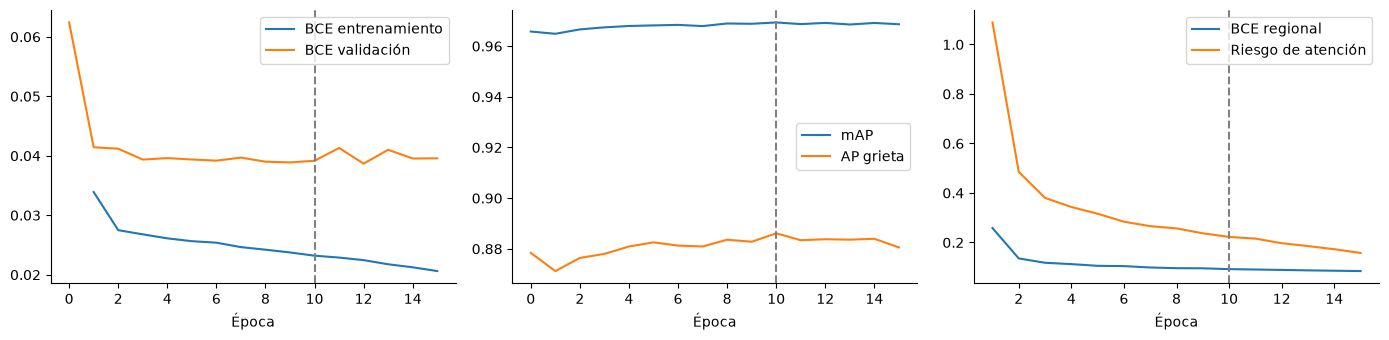

In [15]:
history = pd.read_csv(OUTPUT_DIR / "fusion/history.csv")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(history.epoch, history.train_image_BCE, label="BCE entrenamiento")
axes[0].plot(history.epoch, history.val_BCE, label="BCE validación")
axes[1].plot(history.epoch, history.val_mAP, label="mAP")
axes[1].plot(history.epoch, history.val_crack_AP, label="AP grieta")
axes[2].plot(history.epoch, history.train_regional_BCE, label="BCE regional")
axes[2].plot(history.epoch, history.train_alignment, label="Riesgo de atención")
for axis in axes:
    axis.axvline(run["best_epoch"], color="gray", linestyle="--")
    axis.set_xlabel("Época")
    axis.legend()
fig.tight_layout()
plt.show()

La mAP de validación llega a su máximo en la época 10. Las pérdidas de supervisión regional y de atención siguen bajando después.

## ConvNeXt y la variante en validación

Comparamos el ajuste principal con el ConvNeXt de referencia. Cada modelo usa su umbral F1 para las métricas de decisión. También preparamos los recuentos de grietas manteniendo constantes las falsas alarmas que se muestran después.

In [16]:
reference_probabilities = torch.from_numpy(val_arrays["global_logits"].copy()).sigmoid().numpy()
reference_report = compute_metrics(
    expected_labels, reference_probabilities, global_thresholds, logits=val_arrays["global_logits"]
)
crack_positive = expected_labels[:, 0].astype(bool)
fp_budget = int(((reference_probabilities[:, 0] >= global_thresholds[0]) & ~crack_positive).sum())


def crack_operating_point(logits):
    scores = np.asarray(logits)[:, 0]
    order = np.argsort(-scores, kind="stable")
    ends = np.r_[np.flatnonzero(np.diff(scores[order])), len(scores) - 1]
    fp = np.cumsum(~crack_positive[order])[ends]
    permitted = ends[fp <= fp_budget]
    threshold = float(scores[order[permitted[-1]]]) if len(permitted) else float("inf")
    decisions = scores >= threshold
    return decisions, int((decisions & ~crack_positive).sum())


relative_areas = np.full(len(val_records), np.nan)
for index, record in enumerate(val_records):
    boxes = [box for box in record["boxes"] if box["class_name"] == "crack"]
    if crack_positive[index] and record["localization_valid"] and boxes:
        relative_areas[index] = max(
            (box["xmax"] - box["xmin"]) * (box["ymax"] - box["ymin"]) for box in boxes
        ) / (record["width"] * record["height"])
valid_sizes = np.isfinite(relative_areas)
small_limit = float(np.quantile(relative_areas[valid_sizes], 0.25)) if valid_sizes.any() else None
small = valid_sizes & (relative_areas <= small_limit) if small_limit is not None else valid_sizes

hard = np.isin(expected_ids, hard_ids)

rows = []
for (seed, mode), (directory, result) in runs.items():
    with np.load(directory / "validation.npz", allow_pickle=False) as saved:
        decisions, actual_fp = crack_operating_point(saved["logits"])
        metrics = result["metrics"]
        rows.append(
            {
                "seed": seed,
                "mode": mode,
                "mAP": metrics["overall"]["map"],
                "crack_AP": metrics["per_class"][0]["average_precision"],
                "macro_F1": metrics["overall"]["f1_macro"],
                "healthy_alarms": round(
                    metrics["healthy"]["false_positive_rate_any_label"]
                    * metrics["healthy"]["num_samples"]
                ),
                "crack_FN": int((crack_positive & ~decisions).sum()),
                "actual_crack_FP": actual_fp,
                "FP_budget": fp_budget,
                "small_FN": int((small & ~decisions).sum()),
                "small_support": int(small.sum()),
                "hard_FN": int((hard & ~decisions).sum()),
                "hard_support": int(hard.sum()),
                "best_epoch": result["best_epoch"],
                "completed_epochs": result["completed_epochs"],
                "training_seconds": result["training_seconds"],
            }
        )
seed_results = pd.DataFrame(rows)
metrics_to_summarize = [
    "mAP",
    "crack_AP",
    "macro_F1",
    "healthy_alarms",
    "crack_FN",
    "actual_crack_FP",
    "small_FN",
    "hard_FN",
]
seed_summary = seed_results.groupby("mode")[metrics_to_summarize].agg(["mean", "std"])
paired = seed_results.pivot(index="seed", columns="mode", values=metrics_to_summarize)
paired_differences = pd.DataFrame(
    {
        metric: paired[metric]["balanced"] - paired[metric]["unbalanced"]
        for metric in metrics_to_summarize
    }
)
paired_summary = paired_differences.agg(["mean", "std"]).T.rename(
    columns={"mean": "mean_difference", "std": "std_difference"}
)
display(
    pd.DataFrame(
        {
            "ConvNeXt de referencia": reference_report["overall"],
            "Variante, semilla 42": report["overall"],
        }
    )
)

,ConvNeXt de referencia,"Variante, semilla 42"
num_classes,6.000000,6.000000
map,0.965753,0.969344
precision_macro,0.940092,0.938886
recall_macro,0.937521,0.946767
f1_macro,0.938727,0.942787
precision_micro,0.947700,0.947397
recall_micro,0.944338,0.953342
f1_micro,0.946016,0.950360
hamming_loss,0.013167,0.012167
subset_accuracy,0.926600,0.931200


En validación, la mAP pasa del 96,58 % con ConvNeXt al 96,93 % con la variante. El F1 macro pasa del 93,87 % al 94,28 %.

## Resultados por semilla y modo

La tabla reúne los seis ajustes de fusión. Las columnas de grietas omitidas usan umbrales reajustados al presupuesto de falsas alarmas de ConvNeXt.

In [17]:
print("Falsas alarmas de grieta con el umbral de la referencia:", fp_budget)
display(seed_results)

Falsas alarmas de grieta con el umbral de la referencia: 74


,seed,mode,mAP,crack_AP,macro_F1,healthy_alarms,crack_FN,actual_crack_FP,FP_budget,small_FN,small_support,hard_FN,hard_support,best_epoch,completed_epochs,training_seconds
0,42,balanced,0.969344,0.886127,0.942787,31,91,74,74,67,116,37,37,10,15,20.297523
1,42,unbalanced,0.968693,0.881348,0.943833,34,90,74,74,61,116,36,37,8,13,17.045533
2,43,balanced,0.969731,0.886754,0.945573,24,80,74,74,54,116,36,37,17,22,29.582612
3,43,unbalanced,0.969709,0.885529,0.945150,23,84,74,74,57,116,37,37,18,23,29.959576
4,44,balanced,0.969723,0.888132,0.945282,37,86,74,74,57,116,37,37,14,19,25.231556
5,44,unbalanced,0.969332,0.884910,0.942951,38,95,74,74,63,116,37,37,14,19,25.197512


Los seis ajustes quedan en 74 falsas alarmas de grieta (`actual_crack_FP`). Al equilibrar la atención, las pequeñas omitidas (`small_FN`) pasan de 61 a 67 con la semilla 42 y disminuyen con las semillas 43 y 44.

## Resumen por modo de atención

La tabla muestra, por modo, la media y la desviación estándar de las tres semillas.

In [18]:
display(seed_summary)

mAP            crack_AP            macro_F1            \
                mean       std      mean       std      mean       std   
mode                                                                     
balanced    0.969600  0.000221  0.887004  0.001026  0.944547  0.001531   
unbalanced  0.969245  0.000514  0.883929  0.002257  0.943978  0.001106   

           healthy_alarms             crack_FN           actual_crack_FP       \
                     mean       std       mean       std            mean  std   
mode                                                                            
balanced        30.666667  6.506407  85.666667  5.507571            74.0  0.0   
unbalanced      31.666667  7.767453  89.666667  5.507571            74.0  0.0   

             small_FN              hard_FN           
                 mean       std       mean      std  
mode                                                 
balanced    59.333333  6.806859  36.666667  0.57735  
unbalanced  60.333333  3.055050  36.666667  0.57735

A igual presupuesto de falsas alarmas, la media de omisiones de grieta (`crack_FN`) es de 85,67 con equilibrado y 89,67 sin él.

## Efecto del equilibrado de la atención

Para cada semilla restamos las métricas del modo sin equilibrar a las del modo equilibrado. La tabla resume la media y la desviación estándar de esas diferencias.

In [19]:
display(paired_summary)

,mean_difference,std_difference
mAP,0.000355,0.000316
crack_AP,0.003075,0.001782
macro_F1,0.000569,0.001693
healthy_alarms,-1.000000,2.000000
crack_FN,-4.000000,5.000000
actual_crack_FP,0.000000,0.000000
small_FN,-1.000000,6.244998
hard_FN,0.000000,1.000000


La diferencia media de mAP es de +0,0355 puntos porcentuales. En las grietas difíciles (`hard_FN`), la diferencia media es cero.

## Variante elegida para prueba

Comprobamos una predicción a partir de los píxeles y registramos la configuración y las rutas de los pesos de la variante principal.

In [20]:
manifest_path = OUTPUT_DIR / "manifest.json"
if not manifest_path.exists():
    # A full prediction uses pixels and the two frozen encoders, without annotations.
    record = {
        k: v
        for k, v in val_records[0].items()
        if k not in {"boxes", "labels", "localization_valid"}
    }
    sample = VariantDataset([record], PROJECT_ROOT, normalization)[0]
    classifier = GlobalRegionalClassifier(global_encoder, regional_encoder, model).to(device).eval()
    with torch.inference_mode(), torch.autocast(device.type, enabled=False):
        pixel_output = classifier(
            sample["image"][None].to(device),
            sample["tiles"][None].to(device),
            sample["tile_valid"][None].to(device),
        )
    np.testing.assert_allclose(
        pixel_output["logits"].cpu().numpy(), values["logits"][:1], rtol=1e-4, atol=2e-4
    )
    np.testing.assert_allclose(
        pixel_output["global_logits"].cpu().numpy(),
        val_arrays["global_logits"][:1],
        rtol=1e-4,
        atol=2e-4,
    )
    for name, encoder in (
        ("global_weights", global_encoder),
        ("regional_weights", regional_encoder),
    ):
        assert not encoder.training and not any(p.requires_grad for p in encoder.parameters())
        assert file_hash(PROJECT_ROOT / paths[name]) == encoder_hashes[name]
    selected_files = [
        paths[k]
        for k in (
            "global_weights",
            "global_run",
            "global_validation",
            "regional_weights",
            "regional_run",
        )
    ]
    selected_files += [
        paths["fusion_dir"] + "/" + name for name in ("best.pt", "run.json", "validation.npz")
    ]
    selected_files += [paths[f"features_{split}"] + "/cache.json" for split in ("train", "val")]
    save_json(
        manifest_path,
        {
            "variant": "convnext-reference-global-regional-balanced-attention",
            "status": "complete",
            "inputs": inputs,
            "class_names": list(CLASS_NAMES),
            "data_fingerprint": prepared["data_fingerprint"],
            "normalization": normalization,
            "geometry": geometry,
            "model": {"dimension": dimension, "hidden": CONFIG["hidden"]},
            "paths": paths,
            "source_global_config": global_run["config"],
            "source_regional_config": regional_run["inputs"]["config"],
            "principal_seed": 42,
            "sha256": {name: file_hash(PROJECT_ROOT / name) for name in selected_files},
        },
    )
else:
    selected = json.loads(manifest_path.read_text())
    if selected["data_fingerprint"] != prepared["data_fingerprint"] or any(
        selected["paths"].get(key) != value for key, value in paths.items()
    ):
        raise ValueError("Selected manifest differs from this experiment")
    for name in ("global_weights", "regional_weights"):
        if selected["sha256"][paths[name]] != encoder_hashes[name]:
            raise ValueError("Selected manifest records different encoder weights")
print("Variante seleccionada:", manifest_path.relative_to(PROJECT_ROOT))

Variante seleccionada: outputs/variant_reference_global/manifest.json


## Ejemplos de supervisión regional

Arriba se ven las ventanas y las cajas anotadas sobre la imagen. Debajo se muestran los recortes que recibe el extractor. Las tres columnas ilustran una ventana positiva, una sin supervisión y una negativa para grieta.

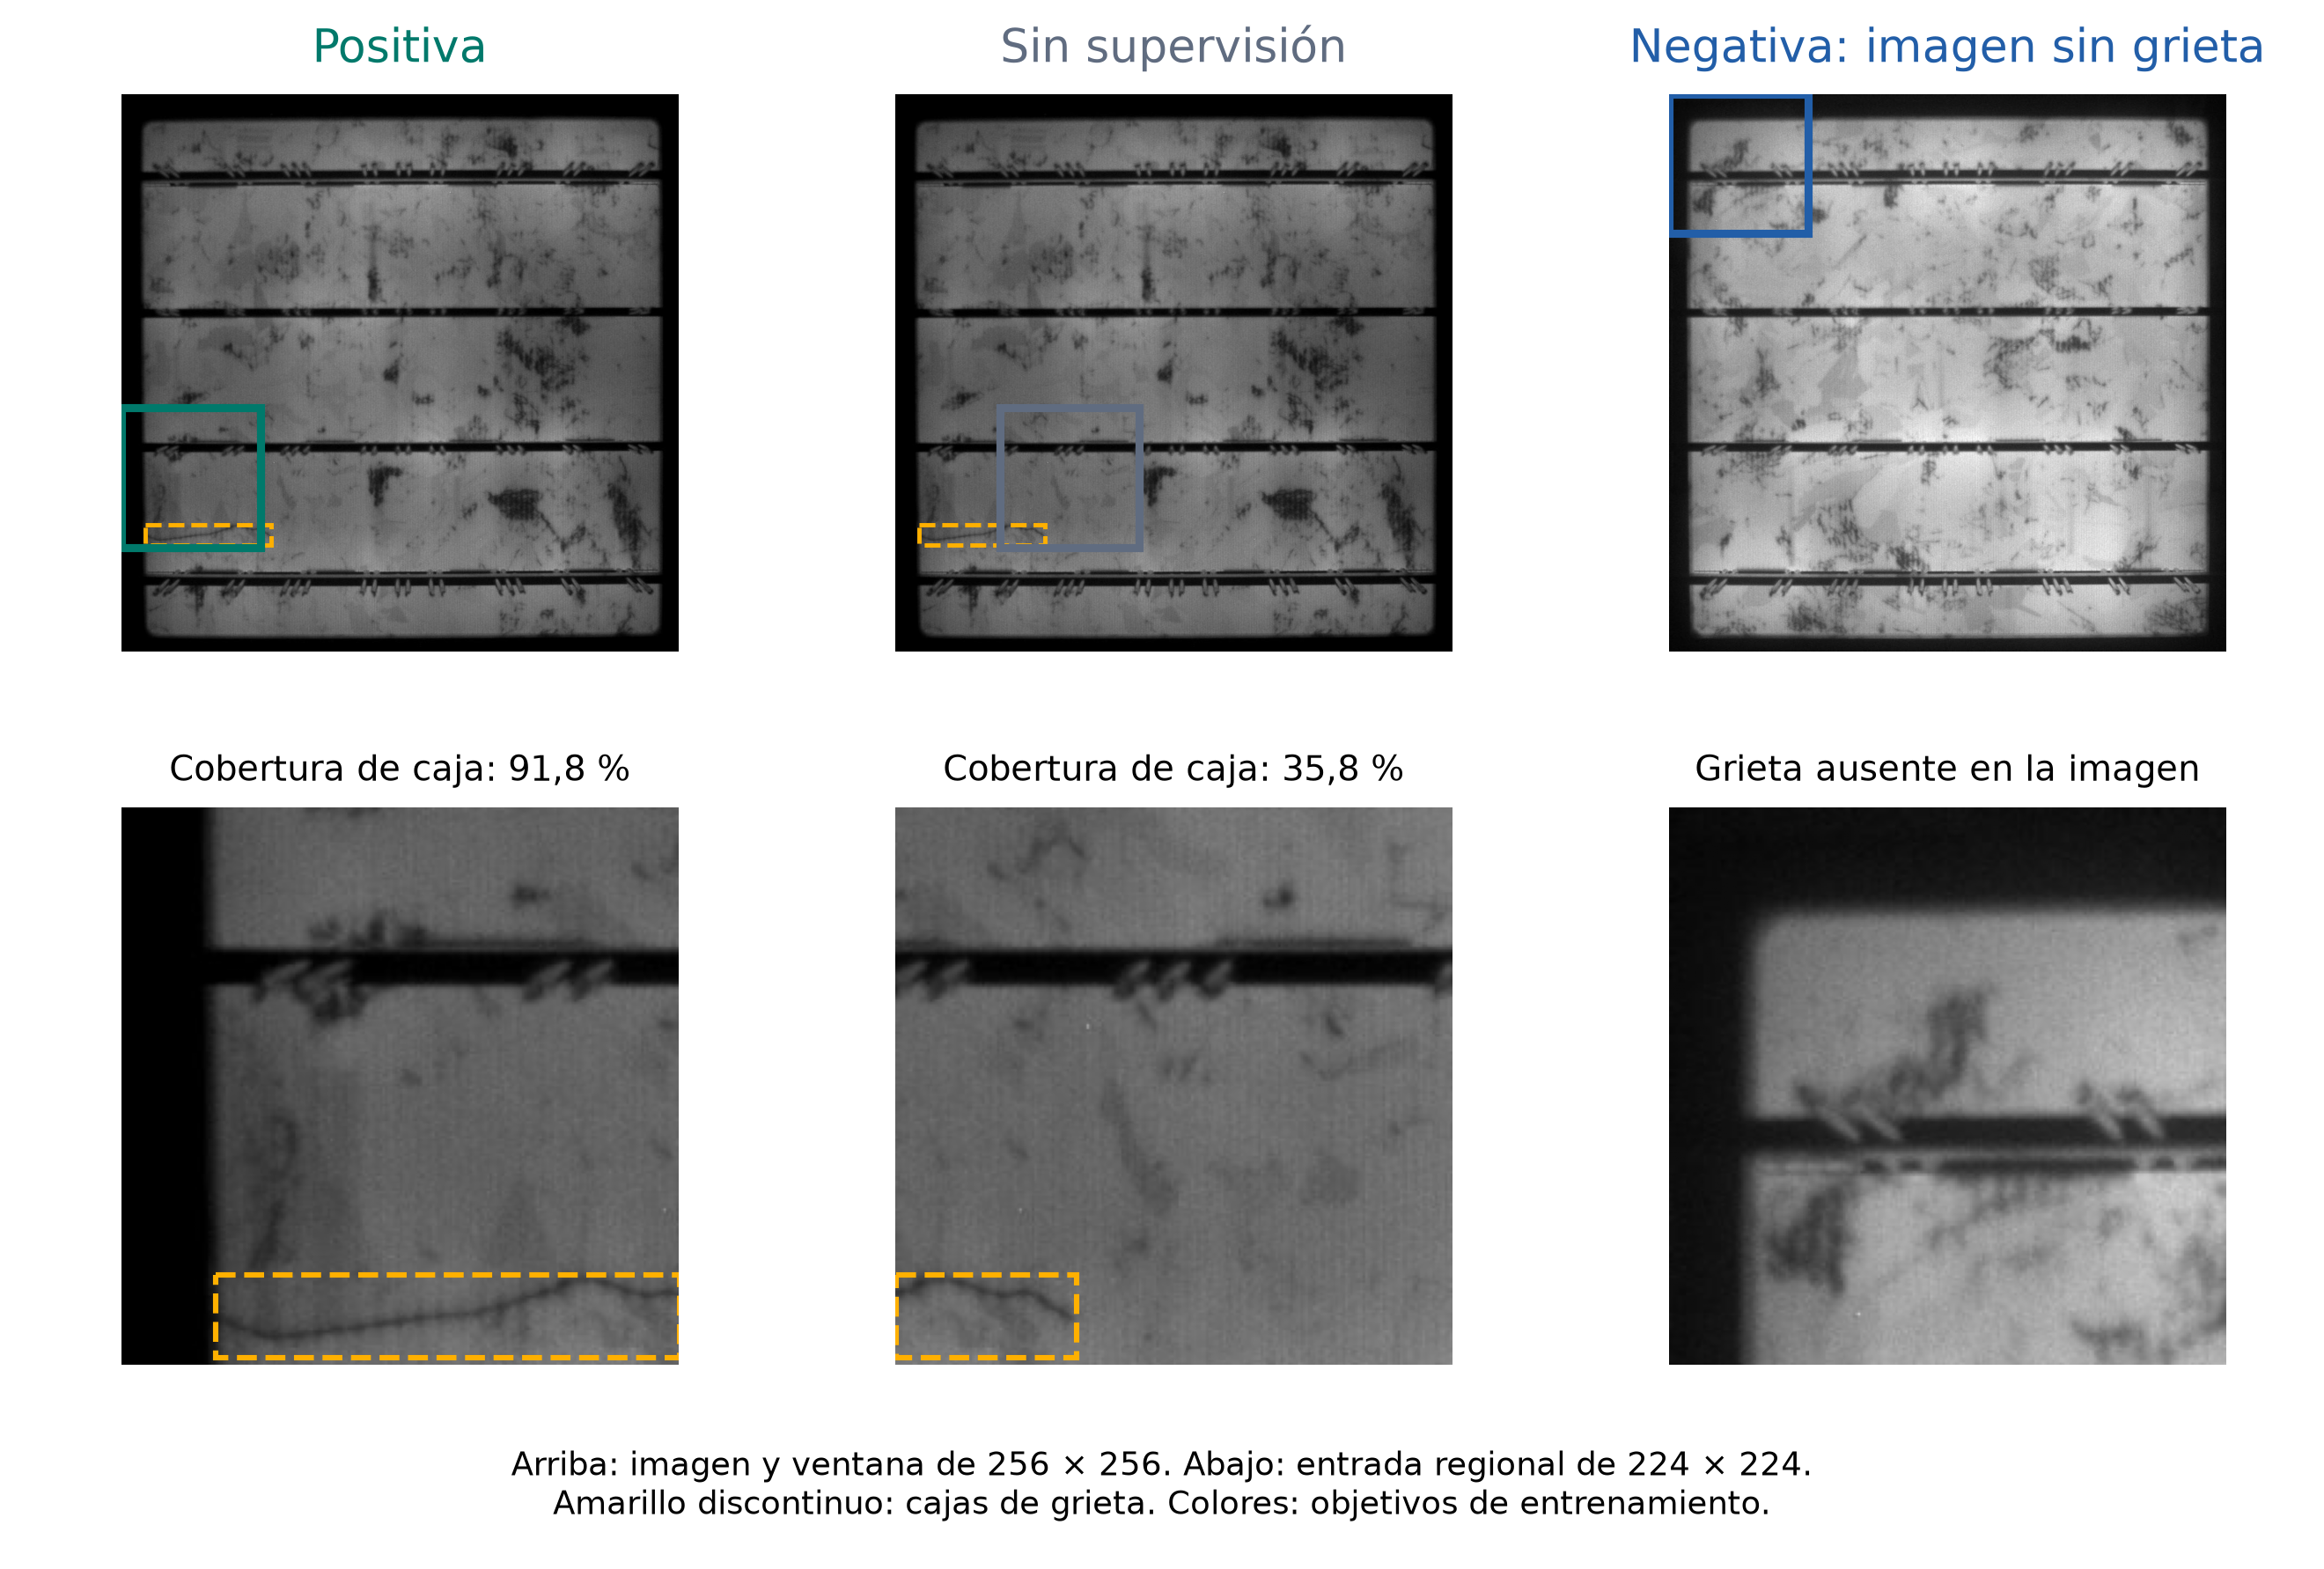

In [21]:
# Use the actual training targets: covered positive, partial unknown, and absent-class negative.
window_bounds, _ = tile_geometry()
for positive_record in sorted(train_records, key=lambda r: r["id"]):
    if not positive_record["localization_valid"] or not positive_record["labels"][0]:
        continue
    sample = VariantDataset([positive_record], PROJECT_ROOT, normalization)[0]
    positive_tiles = torch.nonzero(
        sample["region_known"][:, 0] & sample["region_targets"][:, 0].bool()
    ).flatten()
    unknown_tiles = torch.nonzero(sample["tile_valid"] & ~sample["region_known"][:, 0]).flatten()
    width, height = positive_record["width"], positive_record["height"]
    rw, rh = (
        max(1, round(width * 1024 / max(width, height))),
        max(1, round(height * 1024 / max(width, height))),
    )
    left, top = (1024 - rw) // 2, (1024 - rh) // 2
    references = [
        (
            left + b["xmin"] * rw / width,
            top + b["ymin"] * rh / height,
            left + b["xmax"] * rw / width,
            top + b["ymax"] * rh / height,
        )
        for b in positive_record["boxes"]
        if b["class_name"] == "crack"
    ]
    partial_tiles = []
    for index in unknown_tiles.tolist():
        x0, y0, x1, y1 = window_bounds[index].tolist()
        coverage = max(
            (
                max(0, min(x1, bx1) - max(x0, bx0))
                * max(0, min(y1, by1) - max(y0, by0))
                / ((bx1 - bx0) * (by1 - by0))
                for bx0, by0, bx1, by1 in references
            ),
            default=0,
        )
        if 0 < coverage < 0.5:
            partial_tiles.append(index)
    if len(positive_tiles) and partial_tiles:
        positive_tile, partial_tile = int(positive_tiles[0]), partial_tiles[0]
        break
else:
    raise ValueError("No training example with positive and partially covered crack windows")
negative_record = next(
    r
    for r in sorted(train_records, key=lambda r: r["id"])
    if r["localization_valid"] and not any(r["labels"])
)
negative_sample = VariantDataset([negative_record], PROJECT_ROOT, normalization)[0]
negative_tile = int(torch.nonzero(negative_sample["tile_valid"])[0, 0])
examples = [
    ("Positiva", positive_record, positive_tile, "#00796b"),
    ("Sin supervisión", positive_record, partial_tile, "#606c80"),
    ("Negativa: imagen sin grieta", negative_record, negative_tile, "#225ea8"),
]
supervision_rows = []
with plt.rc_context(figure_style(14)):
    fig, axes = plt.subplots(2, 3, figsize=(12, 8.1))
    for column, (title, record, tile_index, color) in enumerate(examples):
        sample = VariantDataset([record], PROJECT_ROOT, normalization)[0]
        width, height = record["width"], record["height"]
        rw, rh = (
            max(1, round(width * 1024 / max(width, height))),
            max(1, round(height * 1024 / max(width, height))),
        )
        left, top = (1024 - rw) // 2, (1024 - rh) // 2
        boxes = [
            (
                left + b["xmin"] * rw / width,
                top + b["ymin"] * rh / height,
                left + b["xmax"] * rw / width,
                top + b["ymax"] * rh / height,
            )
            for b in record["boxes"]
            if b["class_name"] == "crack"
        ]
        with Image.open(PROJECT_ROOT / record["image_path"]) as opened:
            canvas = letterbox(opened.convert("L"), 1024)
        x0, y0, x1, y1 = window_bounds[tile_index].tolist()
        axes[0, column].imshow(canvas, cmap="gray", vmin=0, vmax=255)
        for bx0, by0, bx1, by1 in boxes:
            axes[0, column].add_patch(
                Rectangle(
                    (bx0, by0),
                    bx1 - bx0,
                    by1 - by0,
                    fill=False,
                    edgecolor="#ffb000",
                    linestyle="--",
                    linewidth=1.6,
                )
            )
        axes[0, column].add_patch(
            Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=color, linewidth=3)
        )
        axes[0, column].set_title(title, color=color, fontsize=17, pad=12)
        mean = torch.tensor(normalization["mean"])[:, None, None]
        std = torch.tensor(normalization["std"])[:, None, None]
        pixels = (sample["tiles"][tile_index] * std + mean)[0].numpy()
        axes[1, column].imshow(pixels, cmap="gray", vmin=0, vmax=1)
        coverage = 0
        for bx0, by0, bx1, by1 in boxes:
            clipped = max(x0, bx0), max(y0, by0), min(x1, bx1), min(y1, by1)
            if clipped[2] > clipped[0] and clipped[3] > clipped[1]:
                coverage = max(
                    coverage,
                    (clipped[2] - clipped[0])
                    * (clipped[3] - clipped[1])
                    / ((bx1 - bx0) * (by1 - by0)),
                )
                axes[1, column].add_patch(
                    Rectangle(
                        ((clipped[0] - x0) * 224 / 256, (clipped[1] - y0) * 224 / 256),
                        (clipped[2] - clipped[0]) * 224 / 256,
                        (clipped[3] - clipped[1]) * 224 / 256,
                        fill=False,
                        edgecolor="#ffb000",
                        linestyle="--",
                        linewidth=2,
                    )
                )
        detail = (
            f"Cobertura de caja: {coverage * 100:.1f} %".replace(".", ",")
            if boxes
            else "Grieta ausente en la imagen"
        )
        axes[1, column].set_title(detail, fontsize=13, pad=10)
        for row in range(2):
            axes[row, column].axis("off")
        supervision_rows.append(
            {
                "role": title,
                "id": record["id"],
                "tile": tile_index,
                "target": int(sample["region_targets"][tile_index, 0]),
                "known": bool(sample["region_known"][tile_index, 0]),
                "box_coverage": coverage,
            }
        )
    fig.subplots_adjust(left=0.015, right=0.995, top=0.94, bottom=0.13, wspace=0.06, hspace=0.28)
    fig.text(
        0.5,
        0.035,
        "Arriba: imagen y ventana de 256 × 256. Abajo: entrada regional de 224 × 224.\n"
        "Amarillo discontinuo: cajas de grieta. Colores: objetivos de entrenamiento.",
        ha="center",
        fontsize=12,
    )
    show_figure(fig, tight=False)

Las dos primeras ventanas salen de la misma imagen. La positiva cubre el 91,8 % de la caja de grieta y la ventana sin supervisión cubre el 35,8 %.

### Etiquetas de las ventanas mostradas

La tabla identifica los recortes de la figura. `target` indica la etiqueta de grieta y `known` indica si el recorte se tiene en cuenta en la pérdida regional.

In [22]:
display(pd.DataFrame(supervision_rows))

,role,id,tile,target,known,box_coverage
0,Positiva,sha_004c4f3b9b897bd7874e707c549e5125ebe4a83064...,15,1,True,0.918103
1,Sin supervisión,sha_004c4f3b9b897bd7874e707c549e5125ebe4a83064...,16,0,False,0.357759
2,Negativa: imagen sin grieta,sha_000f6bdf2c7e0201f7d0d93a389107ea879f3c0675...,0,0,True,0.000000


El recorte central tiene `known=False` y se excluye de la pérdida regional. Los otros dos tienen `known=True` y aportan un ejemplo positivo y otro negativo.

## Grietas omitidas por tamaño

Agrupamos las imágenes con cajas válidas en cuatro intervalos según el área relativa de su mayor caja de grieta. El primer gráfico usa el umbral F1 de cada modelo. El segundo reajusta los umbrales para igualar las falsas alarmas de grieta. Las etiquetas de las barras indican omisiones sobre el número de imágenes del intervalo.

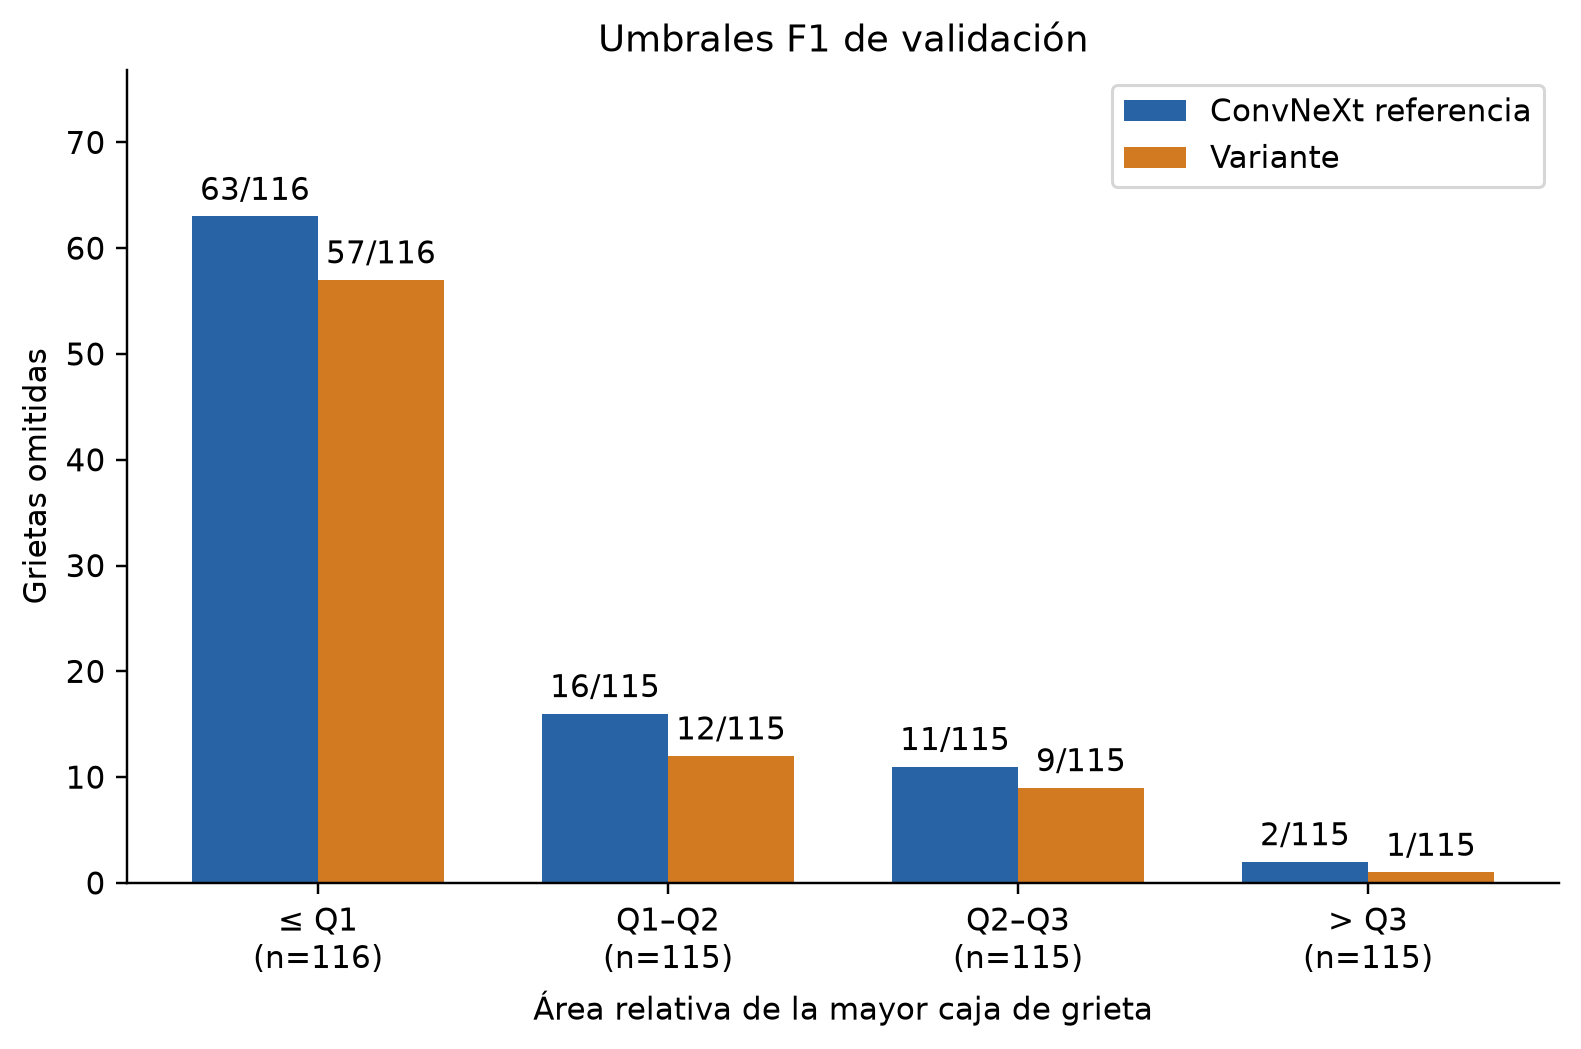

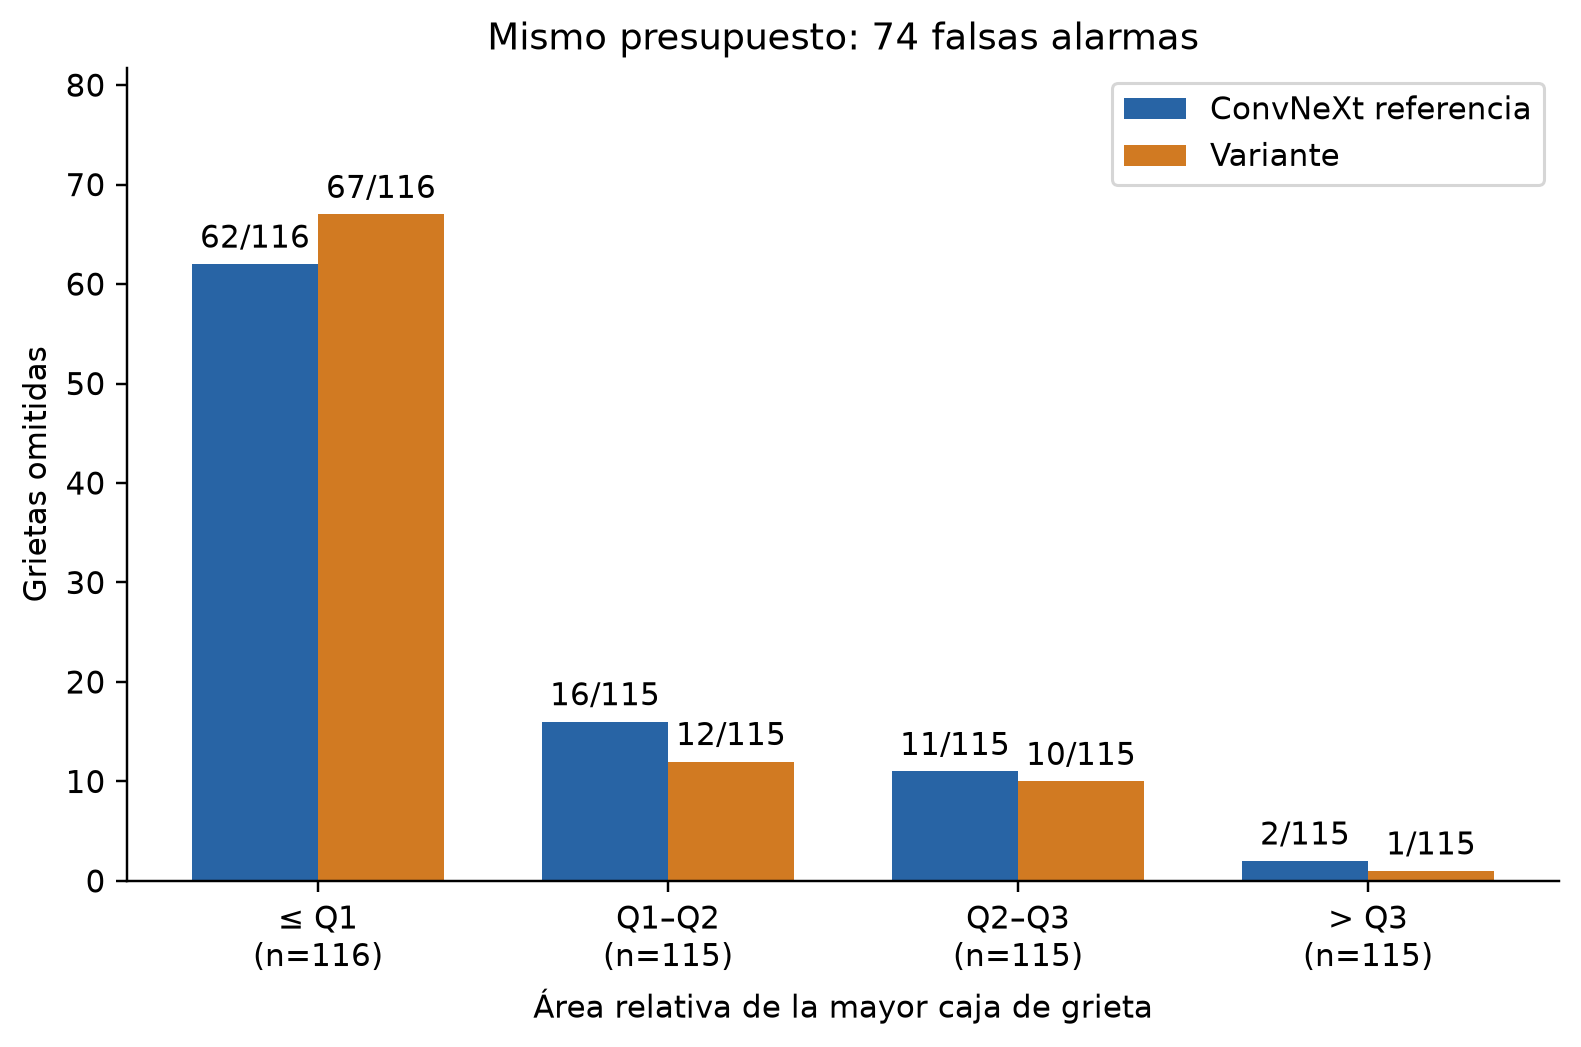

In [23]:
quartiles = np.nanquantile(relative_areas, [0.25, 0.5, 0.75])
size_groups = np.searchsorted(quartiles, relative_areas, side="left")
size_support = np.asarray([(valid_sizes & (size_groups == i)).sum() for i in range(4)])
reference_f1 = reference_probabilities[:, 0] >= global_thresholds[0]
variant_f1 = variant_probabilities[:, 0] >= run["metrics"]["thresholds"][0]
variant_equal_fp, _ = crack_operating_point(values["logits"])
reference_equal_fp, _ = crack_operating_point(val_arrays["global_logits"])
labels = ["≤ Q1", "Q1–Q2", "Q2–Q3", "> Q3"]
size_error_tables = {}
for rule, reference_choices, variant_choices, title in (
    ("f1", reference_f1, variant_f1, "Umbrales F1 de validación"),
    (
        "equal_fp",
        reference_equal_fp,
        variant_equal_fp,
        f"Mismo presupuesto: {fp_budget} falsas alarmas",
    ),
):
    reference_misses = np.asarray(
        [(valid_sizes & (size_groups == i) & ~reference_choices).sum() for i in range(4)]
    )
    variant_misses = np.asarray(
        [(valid_sizes & (size_groups == i) & ~variant_choices).sum() for i in range(4)]
    )
    size_error_tables[rule] = pd.DataFrame(
        {
            "size": labels,
            "support": size_support,
            "reference_misses": reference_misses,
            "variant_misses": variant_misses,
        }
    )
    fig, axis = plt.subplots(figsize=(8.4, 4.8))
    x = np.arange(4)
    for shift, misses, color, name in (
        (-0.18, reference_misses, "#2864a5", "ConvNeXt referencia"),
        (0.18, variant_misses, "#d17a22", "Variante"),
    ):
        bars = axis.bar(x + shift, misses, width=0.36, color=color, label=name)
        axis.bar_label(
            bars,
            labels=[f"{miss}/{support}" for miss, support in zip(misses, size_support)],
            padding=3,
        )
    axis.set_xticks(x, [f"{label}\n(n={support})" for label, support in zip(labels, size_support)])
    axis.set_ylabel("Grietas omitidas")
    axis.set_xlabel("Área relativa de la mayor caja de grieta")
    axis.set_title(title)
    axis.legend()
    axis.set_ylim(0, max(reference_misses.max(), variant_misses.max()) * 1.22)
    show_figure(fig)

Con los umbrales F1, la variante reduce las omisiones en los cuatro intervalos. A 74 falsas alarmas por modelo, se reducen en los tres intervalos por encima de Q1 y aumentan en el de las grietas más pequeñas.

### Recuentos con los umbrales F1

La tabla recoge los valores del primer gráfico. `support` cuenta las imágenes con grieta de cada intervalo y las dos últimas columnas recogen las omisiones de ConvNeXt y de la variante.

In [24]:
display(size_error_tables["f1"])

,size,support,reference_misses,variant_misses
0,≤ Q1,116,63,57
1,Q1–Q2,115,16,12
2,Q2–Q3,115,11,9
3,> Q3,115,2,1


La suma de `support` da 461 imágenes con cajas válidas. En ese subconjunto, la suma de las omisiones baja de 92 con ConvNeXt a 79 con la variante.

### Recuentos a igual presupuesto de falsas alarmas

La tabla conserva los mismos grupos de imágenes y muestra las omisiones del segundo gráfico, a igual presupuesto de falsas alarmas.

In [25]:
display(size_error_tables["equal_fp"])

,size,support,reference_misses,variant_misses
0,≤ Q1,116,62,67
1,Q1–Q2,115,16,12
2,Q2–Q3,115,11,10
3,> Q3,115,2,1


En el primer intervalo (`≤ Q1`), la variante omite 67 de las 116 imágenes y ConvNeXt omite 62. En los otros tres intervalos juntos, las omisiones pasan de 29 a 23.

## Ejemplos de aciertos y omisiones

Mostramos tres ejemplos con el mismo presupuesto de falsas alarmas. La fila inferior amplía la zona de la mayor caja anotada para que se vea la grieta. `TP` indica detección y `FN`, omisión.

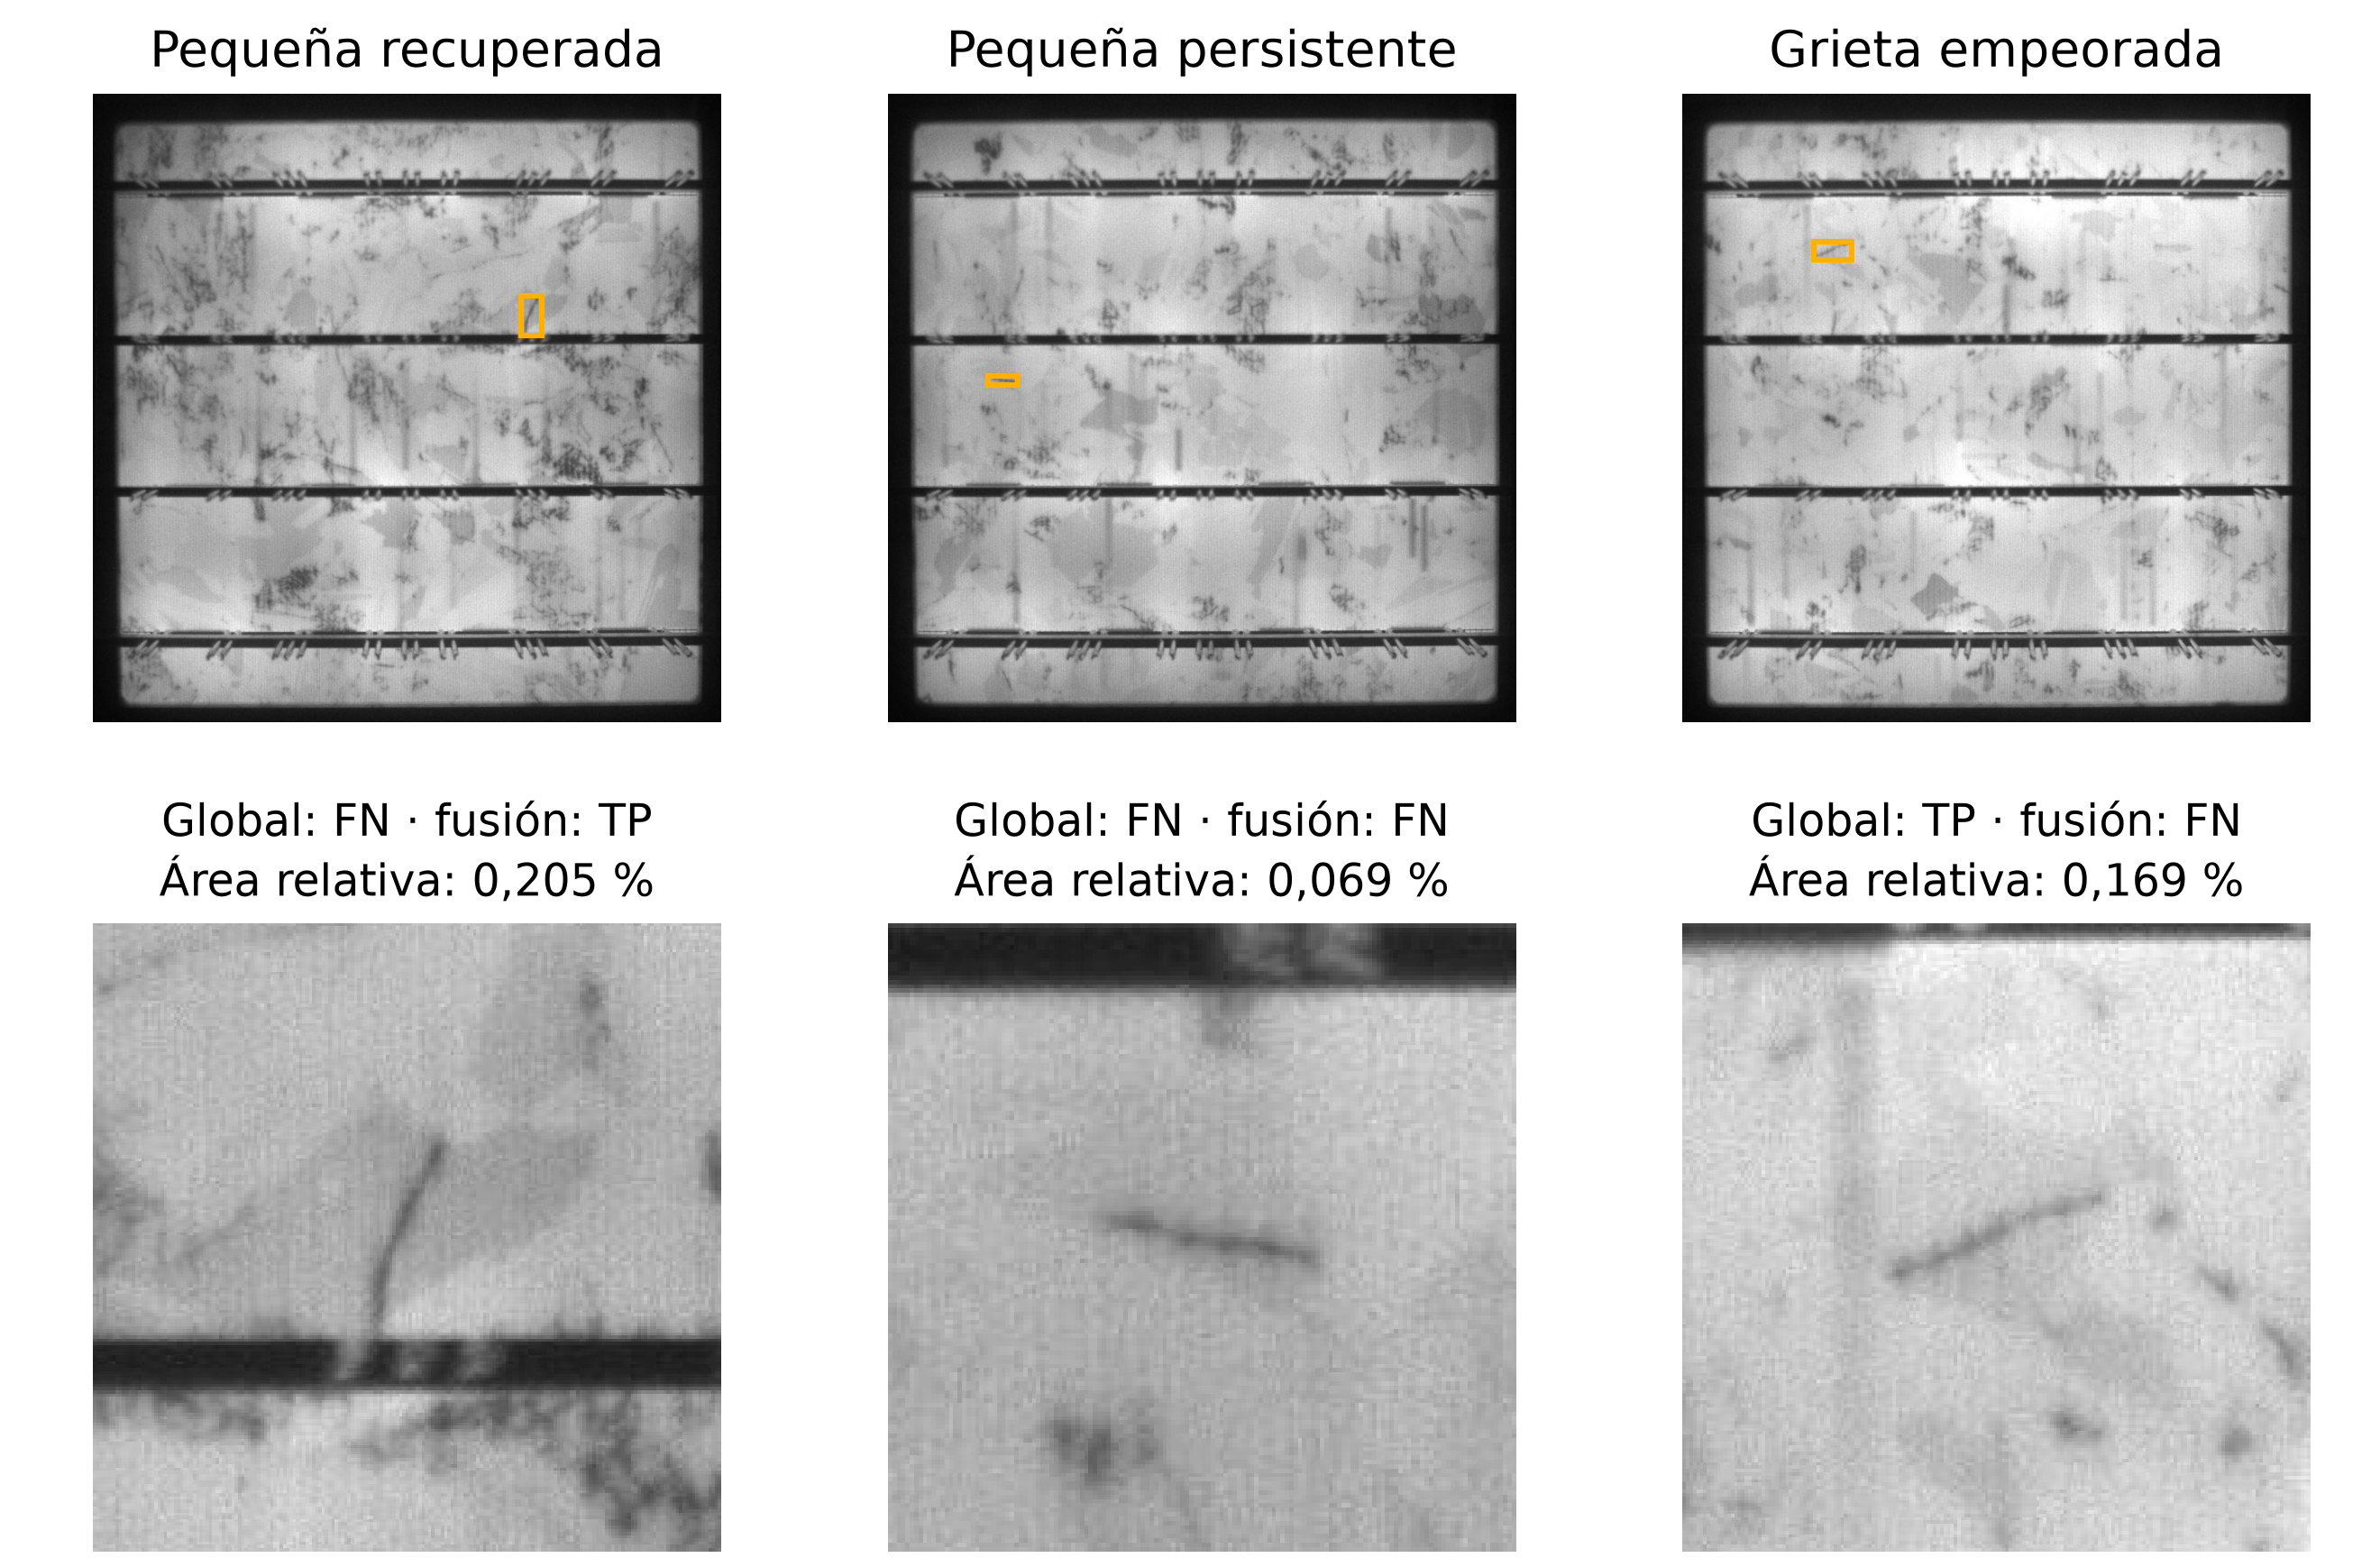

Los detalles se centran en las cajas anotadas para facilitar la comparación.


In [26]:
# First validation case in each transition, at the same false-positive budget.
case_conditions = [
    small & ~reference_equal_fp & variant_equal_fp,
    small & ~reference_equal_fp & ~variant_equal_fp,
    crack_positive & reference_equal_fp & ~variant_equal_fp,
]
case_titles = ["Pequeña recuperada", "Pequeña persistente", "Grieta empeorada"]
case_indices = [int(np.flatnonzero(mask)[0]) if mask.any() else None for mask in case_conditions]
case_rows = []
with plt.rc_context(figure_style(16)):
    fig, axes = plt.subplots(2, 3, figsize=(12, 7.9))
    for column, (index, title) in enumerate(zip(case_indices, case_titles, strict=True)):
        axes[0, column].set_title(title, fontsize=18, pad=10)
        if index is None:
            axes[0, column].text(0.5, 0.5, "Sin casos en validación", ha="center", va="center")
            axes[0, column].axis("off")
            axes[1, column].axis("off")
            continue
        record = val_records[index]
        with Image.open(PROJECT_ROOT / record["image_path"]) as opened:
            image = opened.convert("L")
        boxes = [box for box in record["boxes"] if box["class_name"] == "crack"]
        axes[0, column].imshow(image, cmap="gray", vmin=0, vmax=255)
        for box in boxes:
            axes[0, column].add_patch(
                Rectangle(
                    (box["xmin"], box["ymin"]),
                    box["xmax"] - box["xmin"],
                    box["ymax"] - box["ymin"],
                    fill=False,
                    edgecolor="#ffb000",
                    linewidth=2,
                )
            )
        axes[0, column].axis("off")
        box = max(boxes, key=lambda b: (b["xmax"] - b["xmin"]) * (b["ymax"] - b["ymin"]))
        area = (
            (box["xmax"] - box["xmin"])
            * (box["ymax"] - box["ymin"])
            / (record["width"] * record["height"])
        )
        side = max(
            3 * (box["xmax"] - box["xmin"]), 3 * (box["ymax"] - box["ymin"]), record["width"] / 8
        )
        cx, cy = (box["xmin"] + box["xmax"]) / 2, (box["ymin"] + box["ymax"]) / 2
        detail = image.crop(
            (
                max(0, cx - side / 2),
                max(0, cy - side / 2),
                min(image.width, cx + side / 2),
                min(image.height, cy + side / 2),
            )
        )
        axes[1, column].imshow(detail, cmap="gray", vmin=0, vmax=255)
        axes[1, column].axis("off")
        reference_state = "TP" if reference_equal_fp[index] else "FN"
        variant_state = "TP" if variant_equal_fp[index] else "FN"
        area_label = f"{100 * area:.3f}".replace(".", ",")
        axes[1, column].set_title(
            f"Global: {reference_state} · fusión: {variant_state}\nÁrea relativa: {area_label} %",
            fontsize=16,
            pad=10,
        )
        case_rows.append(
            {
                "case": title,
                "id": record["id"],
                "global": reference_state,
                "fusion": variant_state,
                "relative_area": area,
                "FP_budget": fp_budget,
            }
        )
    fig.subplots_adjust(left=0.015, right=0.995, bottom=0.01, top=0.94, wspace=0.07, hspace=0.32)
    show_figure(fig, tight=False)
print("Los detalles se centran en las cajas anotadas para facilitar la comparación.")

La fusión recupera el caso de la izquierda. La grieta central sigue sin detectarse y la de la derecha pasa de detectada a omitida.

### Resultados de las imágenes mostradas

La tabla identifica cada imagen y recoge las decisiones de ambos modelos. `relative_area` es la fracción de la imagen que ocupa la mayor caja de grieta.

In [27]:
display(pd.DataFrame(case_rows))

,case,id,global,fusion,relative_area,FP_budget
0,Pequeña recuperada,sha_171cf090fb500b493537b0e251895c36edacda35d5...,FN,TP,0.002046,74
1,Pequeña persistente,sha_019e108ddff464f32b704c5913686a9d3df42fe11f...,FN,FN,0.000687,74
2,Grieta empeorada,sha_15378512479c0d475d206f881a3e6794ad3de350b6...,TP,FN,0.001687,74


`FP_budget` vale 74 para las tres filas. La grieta que ambos modelos omiten tiene la menor área relativa de los tres ejemplos, alrededor del 0,069 % de la imagen.

En el [cuaderno 05](05_test_and_cost.ipynb) evaluamos la variante principal en prueba con los pesos y umbrales F1 elegidos en validación.